# Figure 13 — Non-Gaussianity, neurons firing 20–100 Hz

Pena, Vellmer, Bernardi, Roque & Lindner (2018), Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009. Scheme after Dummer, Wieland & Lindner (2014).

**Caption (paper):** As Figure 12, restricted to neurons firing between 20 and 100 Hz, where correlations are higher.

**Method here:** input currents of 1,000 E neurons recorded in the Figure 11 networks (N_E = 10,000, 10 windows of 2 s); isolated LIF neurons driven by Gaussian noise with each neuron's mean input and input spectrum (20 trials). Error uses f_cut = 2ν of each neuron. The input-distribution inset is not reproduced.

**Shared implementation choices** (all figures, see `pena_scheme.py`, `pena_network.py`):
- Euler, `dt = 0.1 ms`; voltage clamped at reset during the refractory period (scheme and network).
- Spectra: Eq. 5, two-sided, 2 s windows after a 1 s transient (Δf = 0.5 Hz).
  Fano factor = mean of S at 0.5 and 1 Hz divided by ν; τc from Eq. 7 with the estimator variance subtracted.
- Scheme generation 0: white noise at the diffusion-approximation (mean-field) rate; the paper does not
  specify its starting point. Inhibition-dominated cases (g > 4) use the all-past rate average (Eq. 11).
- Networks are simulated at reduced size (default N_E = 10,000 instead of 100,000) to fit 2 CPUs / ~2 GB;
  partners are drawn with replacement. Larger sizes are available via the config cell but need far more memory.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
import pena_runs as pr
FIGURES = HERE / "figures"; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
G_VALUES = [4.0, 6.0]
N_E_NET, N_WINDOWS = 10_000, 10
RATE_WINDOW = (20.0, 100.0)   # (low, high) Hz or None

In [3]:
data = {}
for g in G_VALUES:
    net = pr.er_network(g, "exponential", N_E_NET, N_WINDOWS)
    sur = pr.gaussian_surrogate(g, net)
    f = net["f"]; nu = net["in_rates"]
    ok = nu > 0.5
    if RATE_WINDOW: ok &= (nu >= RATE_WINDOW[0]) & (nu <= RATE_WINDOW[1])
    idx = np.flatnonzero(ok)
    err = np.array([ps.relative_error(f, net["in_S_spk"][j], sur["S"][j], 2 * nu[j]) for j in idx])
    low = np.array([ps.relative_error(f, net["half0"][j], net["half1"][j], 2 * nu[j]) for j in idx])
    data[g] = dict(err=err, low=low, skew=net["in_skew"][idx], kurt=net["in_kurt"][idx], nu=nu[idx])
    print(f"g={g}: {idx.size} neurons, mean error {err.mean():.3f}, lower bound {low.mean():.3f}")

loaded net_er_84eca4c5ec.npz


loaded surrogate_d78ab01b12.npz
g=4.0: 556 neurons, mean error 0.129, lower bound 0.335
loaded net_er_25186880b0.npz


loaded surrogate_4e39c532dc.npz
g=6.0: 298 neurons, mean error 0.130, lower bound 0.328


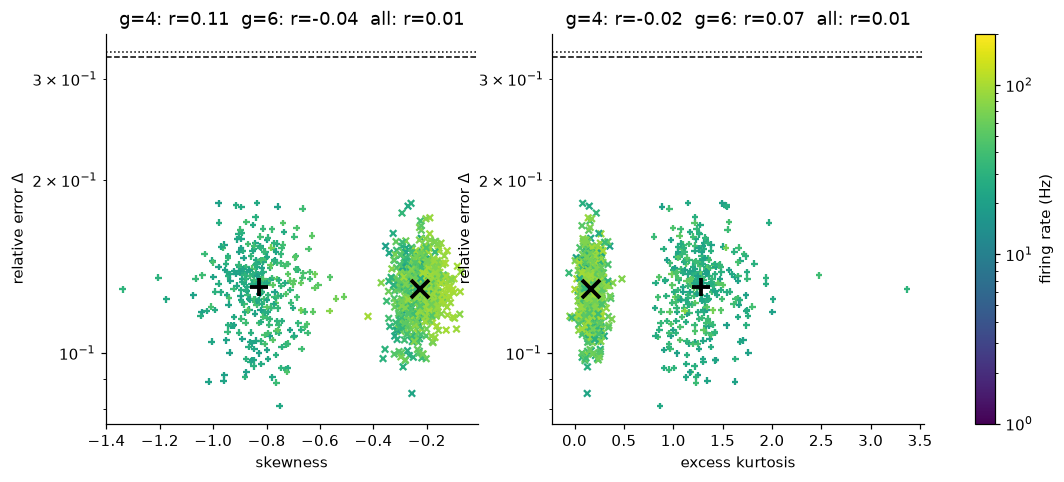

saved figure13_non_gaussianity_20_100Hz.csv (1712 data points)


PosixPath('/workspaces/SC_Cortex/05_Pena2018_Replication/figures/figure13_non_gaussianity_20_100Hz.csv')

In [4]:
from matplotlib.colors import LogNorm
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
norm = LogNorm(1, 200)
for ax, key, lab in [(axes[0], "skew", "skewness"), (axes[1], "kurt", "excess kurtosis")]:
    title = []
    for g, mk in zip(G_VALUES, ["x", "+"]):
        d = data[g]
        sc = ax.scatter(d[key], d["err"], c=np.clip(d["nu"], 1, 200), norm=norm, cmap="viridis", marker=mk, s=18)
        ax.plot(d[key].mean(), d["err"].mean(), marker=mk, color="k", ms=12, mew=2.5)
        ax.axhline(d["low"].mean(), color="k", ls=":" if g == 4 else "--", lw=1)
        title.append(f"g={g:g}: r={np.corrcoef(d[key], np.log(d['err']))[0, 1]:.2f}")
    allx = np.concatenate([data[g][key] for g in G_VALUES]); ally = np.concatenate([data[g]["err"] for g in G_VALUES])
    title.append(f"all: r={np.corrcoef(allx, np.log(ally))[0, 1]:.2f}")
    ax.set(yscale="log", xlabel=lab, ylabel="relative error Δ", title="  ".join(title))
fig.colorbar(sc, ax=axes, label="firing rate (Hz)")
fig.savefig(FIGURES / "figure13_non_gaussianity_20_100Hz.png", dpi=200, bbox_inches="tight"); plt.show()
import pena_export; pena_export.figure_csv(fig, FIGURES / "figure13_non_gaussianity_20_100Hz.csv")

Pearson coefficients are computed between the measure and log(Δ); dotted/dashed lines are the mean lower bound for g = 4 / 6.

## Notes

_Filled in after the run._